# Final evaluation on April 2026

**IDX Exchange | Week 8**

This notebook scores the April 2026 test month once, with every model frozen before April was looked at. The lock-in commit is `8d41984` ("lock final model before april test"), which contains `results/final_model_config.json`. Each model is refit on all sales from January 2024 through March 2026 and scored on April's 12,022 single-family sales.

The final model, **XGBoost** on Dataset B without the ratios, reaches **7.70% MdAPE** on April (filtered scope), against 16.46% for the Week 4 linear baseline. It prices 60.4% of April homes within 10% of the sale price and 85.5% within 20%, against 32.3% and 58.5% for the baseline. R² is 0.898 against 0.817. Its March validation MdAPE was 7.76%, and the backtests ranged from 7.57% to 7.90%, so April is in line with every month seen during development.

XGBoost is clearly ahead of the baseline, the log-log model, the decision tree and the Week 5 forest (all paired-bootstrap intervals exclude zero). It is statistically tied with the Week 6 forest (0.12 points better, interval −0.25 to +0.04) and with LightGBM (0.06 points worse, −0.08 to +0.19). LightGBM's April MdAPE is the lowest of all, at 7.65%. The final model stays XGBoost: it was chosen under a rule fixed before April, and switching now would turn the test month into a selection set.

The weak spots are the same as before. The top 1% of sales ($6.62M and up) are under-predicted by a median of 38%, and two-thirds of them sold above the highest training price. Error also rises with price and with property age, and Oakland and the Bay Area counties are the hardest markets.

## 1. Setup

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import HTML, display

sys.path.insert(0, str(Path("../src").resolve()))
import avm  # noqa: E402

DATA_DIR = Path("../data/raw")
DISTRICT_SHAPEFILE = Path("../data/external/school_districts_2024_25/DistrictAreas2425.shp")
DISTRICT_CACHE = Path("../data/processed/school_district_by_location.csv")
RESULTS_DIR = Path("../results")
SUMMARY_PATH = RESULTS_DIR / "metrics_summary.csv"
APRIL_BOOTSTRAP_PATH = RESULTS_DIR / "april_bootstrap.csv"
APRIL_CONTEXT_PATH = RESULTS_DIR / "april_test_context.json"
# Per-sale April predictions are licensed CRMLS records: kept locally, ignored by git.
APRIL_PREDICTIONS_PATH = RESULTS_DIR / "april_predictions.csv"

TARGET = avm.TARGET
VAL_MONTH, TEST_MONTH = avm.TEAM_VAL_MONTH, avm.TEAM_TEST_MONTH
DEV_MONTHS = avm.TEAM_BACKTEST_MONTHS + [VAL_MONTH]
EXPECTED_FINGERPRINT = "66cab54017ab"   # all 28 files, January 2024 – April 2026
EXPECTED_CLEAN_ROWS = 309_039           # with re-reported sales dropped
EXPECTED_APRIL_ROWS = 12_022
LOCK_COMMIT = "8d41984"                 # "lock final model before april test"

# Backtest and validation refits are cached; set this to rebuild them. April is
# scored once: once its predictions exist they are loaded, never refit.
RERUN_BACKTESTS = False
N_BOOTSTRAP = 1_000

final_config = json.loads((RESULTS_DIR / "final_model_config.json").read_text())
FEATURES = avm.FeatureSet(final_config["features"]["name"], tuple(final_config["features"]["numeric"]),
                          tuple(final_config["features"]["categorical"]))
assert FEATURES == avm.FEATURES_WITHOUT_RATIOS
A = avm.BASE_FEATURES

LINEAR, LOG_LINEAR, TREE, FOREST = avm.LINEAR, avm.LOG_LINEAR, avm.TREE, avm.FOREST
LIGHTGBM, XGBOOST = avm.LIGHTGBM, avm.XGBOOST
FOREST_A = "Random forest (Week 5 features)"
FINAL = final_config["model"]
assert FINAL == XGBOOST and final_config["log_target"]

TREE_PARAMS = {"max_depth": 18, "min_samples_leaf": 50}
FOREST_PARAMS = {"n_estimators": 200, "max_features": 0.5, "min_samples_leaf": 5, "max_depth": None}
LIGHTGBM_PARAMS = {"learning_rate": 0.1, "num_leaves": 127, "n_estimators": 1500, "min_child_samples": 100}
XGBOOST_PARAMS = final_config["params"]

# Every model exactly as it was frozen: (feature set, where it was frozen, configuration, factory).
SPECS = {
    LINEAR: (A, "Week 4 (notebook 03)", "Week 4 specification", lambda: avm.make_linear_model(False, A)),
    LOG_LINEAR: (A, "Week 4 (notebook 03)", "Week 4 specification", lambda: avm.make_linear_model(True, A)),
    TREE: (A, "Week 5 (notebook 04)", avm.describe_config(TREE_PARAMS, True),
           avm.tree_factory(TREE, TREE_PARAMS, True, A)),
    FOREST_A: (A, "Week 5 (notebook 04)", avm.describe_config(FOREST_PARAMS, True),
               avm.tree_factory(FOREST, FOREST_PARAMS, True, A)),
    FOREST: (FEATURES, "Week 6 (notebook 05)", avm.describe_config(FOREST_PARAMS, True),
             avm.tree_factory(FOREST, FOREST_PARAMS, True, FEATURES)),
    LIGHTGBM: (FEATURES, "Week 7 (notebook 06)", avm.describe_config(LIGHTGBM_PARAMS, True),
               avm.tree_factory(LIGHTGBM, LIGHTGBM_PARAMS, True, FEATURES)),
    XGBOOST: (FEATURES, "Week 7 (notebook 06), final", avm.describe_config(XGBOOST_PARAMS, True),
              avm.tree_factory(XGBOOST, XGBOOST_PARAMS, True, FEATURES)),
}
MODEL_ORDER = list(SPECS)
FACTORIES = {name: spec[3] for name, spec in SPECS.items()}
PARAMS = {name: f"{spec[0].name} | {spec[2]}" for name, spec in SPECS.items()}

# The configurations must match what notebooks 04 and 06 saved.
week5 = pd.read_csv(RESULTS_DIR / "model_comparison_metrics.csv").drop_duplicates("model").set_index("model")["params"]
week7 = pd.read_csv(RESULTS_DIR / "advanced_model_metrics.csv").drop_duplicates("model").set_index("model")["params"]
assert week5[TREE] == SPECS[TREE][2] and week5[FOREST] == SPECS[FOREST_A][2]
assert all(week7[name] == SPECS[name][2] for name in (FOREST, LIGHTGBM, XGBOOST))

NAMES = {**avm.DISPLAY_NAMES, FOREST: "Random forest (Week 6 features)", FOREST_A: FOREST_A,
         XGBOOST: "XGBoost (final)"}
COLORS = {**avm.MODEL_COLORS, FOREST_A: "#8fbf9f"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
print("pandas", pd.__version__, "| sklearn", sklearn.__version__)
display(pd.DataFrame({"Frozen in": [s[1] for s in SPECS.values()],
                      "Features": [s[0].name for s in SPECS.values()],
                      "Configuration": [s[2] for s in SPECS.values()]}, index=MODEL_ORDER))

pandas 3.0.6 | sklearn 1.9.1


,Frozen in,Features,Configuration
Linear regression,Week 4 (notebook 03),A,Week 4 specification
Log-log linear regression,Week 4 (notebook 03),A,Week 4 specification
Decision tree,Week 5 (notebook 04),A,"max_depth=18, min_samples_leaf=50, target=log ..."
Random forest (Week 5 features),Week 5 (notebook 04),A,"n_estimators=200, max_features=0.5, min_sample..."
Random forest,Week 6 (notebook 05),B without ratios,"n_estimators=200, max_features=0.5, min_sample..."
LightGBM,Week 7 (notebook 06),B without ratios,"learning_rate=0.1, num_leaves=127, n_estimator..."
XGBoost,"Week 7 (notebook 06), final",B without ratios,"learning_rate=0.1, max_depth=10, n_estimators=..."


**Evaluation protocol.** Backtests at December 2025, January 2026 and February 2026; validation on March 2026; test on April 2026, the month the team agreed to share. March was the Week 5 test month in notebook 04 and became the validation month in Week 6 to match the team. April was not looked at before this notebook: notebooks 04–06 fingerprinted its file and set it aside before cleaning. Every cutoff trains on all earlier months, filtered to the training months' 0.5th–99.5th percentile price bounds. "Filtered" scores sales inside those frozen bounds, and "all" scores every valid sale; both are reported, with coverage.

Every model is scored exactly as it was frozen, so the table shows the whole project's progression:

- Linear regression (the Week 4 baseline) and log-log linear regression: the Week 4 specification on Dataset A.
- Decision tree and random forest: the Week 5 configurations on Dataset A.
- The same random forest on the Week 6 feature set.
- LightGBM and XGBoost: the Week 7 configurations on the Week 6 feature set.

The setup cell checks every configuration against what notebooks 04 and 06 saved.

## 2. Data

The full pull, April included, is loaded and cleaned with the re-reported-sale rule. Four April sales repeat a March sale of the same listing and are dropped, leaving 12,022 April sales. School districts for April's new listings are joined against the same 2024-25 boundaries, and the cache is extended.

In [2]:
raw, snapshot, fingerprint = avm.load_raw(DATA_DIR)
assert fingerprint == EXPECTED_FINGERPRINT, f"Data pull changed: {fingerprint}"
df, cleaning_steps, set_missing = avm.clean(raw, drop_rereported=True)
assert len(df) == EXPECTED_CLEAN_ROWS, f"Cleaning changed: {len(df):,} rows"
df, newly_joined = avm.attach_school_districts(df, DISTRICT_CACHE, DISTRICT_SHAPEFILE)
df["County"] = avm.clean_text(df["CountyOrParish"])
df["AgeAtSale"] = df["SaleYear"] - df["YearBuilt"]
in_april = df["CloseMonth"] == TEST_MONTH
assert in_april.sum() == EXPECTED_APRIL_ROWS and df["CloseMonth"].max() == TEST_MONTH

rereported = cleaning_steps.attrs["rereported"]
print(f"{len(df):,} sales, January 2024 – April 2026 (snapshot {fingerprint}); "
      f"{in_april.sum():,} in April after dropping {(rereported['CloseMonth'] == TEST_MONTH).sum()} "
      "re-reported April copies")
print(f"{newly_joined:,} listing locations newly joined to school districts (April's new listings)")
april_located = df.loc[in_april, "Latitude"].notna()
print(f"April district match rate among sales with usable coordinates: "
      f"{df.loc[in_april & df['Latitude'].notna(), 'SchoolDistrict'].notna().mean():.2%}")

309,039 sales, January 2024 – April 2026 (snapshot 66cab54017ab); 12,022 in April after dropping 4 re-reported April copies
0 listing locations newly joined to school districts (April's new listings)
April district match rate among sales with usable coordinates: 99.99%


## 3. Backtests and validation

Before April is scored, every model is refit at the four development cutoffs. These refits produce the backtest and validation rows of `metrics_summary.csv`, and the stability view at the end. The models that notebooks 05 and 06 also ran must reproduce those results exactly, which is checked here before April is touched.

In [3]:
METRIC_COLUMNS = ["R2", "MAE_USD", "RMSE_USD", "MAPE_pct", "MdAPE_pct", "PPE10_pct", "PPE20_pct",
                  "median_bias_pct", "N"]


def tidy(run):
    rows = avm.metric_records(run, PARAMS, val_month=VAL_MONTH, test_month=TEST_MONTH)
    out = pd.DataFrame(rows)
    out["features"] = out["params"].str.split(" | ", regex=False).str[0]
    out["params"] = out["params"].str.split(" | ", regex=False).str[1]
    out["clean_rows"] = len(df)
    return out[["model", "features", "params", "split", "month", "scope", "coverage"] + METRIC_COLUMNS
               + ["clean_rows"]]


def is_current(rows, months):
    if rows.empty or sorted(rows["month"].unique()) != sorted(months):
        return False
    labels = (rows["features"] + " | " + rows["params"]).groupby(rows["model"]).first().to_dict()
    return labels == PARAMS and (rows["clean_rows"] == len(df)).all()


summary = (pd.read_csv(SUMMARY_PATH, dtype={"month": str}) if SUMMARY_PATH.exists()
           else pd.DataFrame(columns=["split", "month"]))
dev = summary.loc[summary["split"] != "test"]
if RERUN_BACKTESTS or not is_current(dev, DEV_MONTHS):
    dev = pd.concat([tidy(avm.run_cutoff(df, month, FACTORIES, inputs=FEATURES)) for month in DEV_MONTHS],
                    ignore_index=True)
    print("Backtests and validation refit")
else:
    print("Backtests and validation loaded from metrics_summary.csv")

# Models that notebooks 05 and 06 ran on the same rows and cutoffs must reproduce them.
week7 = pd.read_csv(RESULTS_DIR / "advanced_model_metrics.csv", dtype={"month": str}).query(
    "model in [@FOREST, @LIGHTGBM, @XGBOOST]")
week6 = pd.read_csv(RESULTS_DIR / "feature_set_metrics.csv", dtype={"month": str}).query(
    "feature_set == 'A'").replace({"model": {FOREST: FOREST_A}})
for earlier, n_models in ((week7, 3), (week6, 2)):
    check = dev.merge(earlier, on=["model", "month", "scope"], suffixes=("", "_before"))
    assert len(check) == n_models * 2 * len(DEV_MONTHS)
    assert np.allclose(check["MdAPE_pct"], check["MdAPE_pct_before"], atol=1e-9)
    assert (check["N"] == check["N_before"]).all()
print("Forest, LightGBM and XGBoost reproduce notebook 06; the Week 5-feature forest and "
      "log-log model reproduce notebook 05")

by_month = dev.query("scope == 'filtered'").pivot(index="model", columns="month", values="MdAPE_pct")
display(by_month.loc[MODEL_ORDER, DEV_MONTHS].map("{:.2f}".format))

Backtests and validation loaded from metrics_summary.csv
Forest, LightGBM and XGBoost reproduce notebook 06; the Week 5-feature forest and log-log model reproduce notebook 05


month,202512,202601,202602,202603
model,,,,
Linear regression,16.76,17.11,16.79,16.61
Log-log linear regression,10.09,10.59,10.60,10.04
Decision tree,10.39,10.49,10.65,10.09
Random forest (Week 5 features),9.33,9.37,9.54,9.17
Random forest,7.87,7.96,8.11,7.83
LightGBM,7.70,7.56,7.80,7.71
XGBoost,7.68,7.57,7.90,7.76


## 4. April 2026 test

Every model is trained on all 294,072 sales from January 2024 through March 2026 that fall inside the training price bounds ($190,000 to $8,300,000), then scored once on April. The block below scores April only if its results don't exist yet. Once the per-sale predictions are written, a rerun loads them; a rerun with different settings stops instead of rescoring.

In [4]:
test = summary.loc[summary["split"] == "test"]
if not is_current(test, [TEST_MONTH]):
    if APRIL_PREDICTIONS_PATH.exists():
        raise RuntimeError("April has already been scored with different settings; it is not rescored.")
    run = avm.run_cutoff(df, TEST_MONTH, FACTORIES, inputs=FEATURES)
    test = tidy(run)
    evaluate, mask = run["evaluate"], run["in_range"]
    y_true = evaluate.loc[mask, TARGET]
    rows = []
    for name in MODEL_ORDER:
        if name == FINAL:
            continue
        diffs = avm.paired_bootstrap_mdape_diff(y_true, run["results"][FINAL]["pred"].loc[mask],
                                                run["results"][name]["pred"].loc[mask], N_BOOTSTRAP)
        rows.append({"model": FINAL, "versus": name,
                     "mdape_change": run["results"][FINAL]["filtered"]["MdAPE_pct"]
                     - run["results"][name]["filtered"]["MdAPE_pct"],
                     "ci_low": np.percentile(diffs, 2.5), "ci_high": np.percentile(diffs, 97.5),
                     "share_favoring_final": 100 * (diffs < 0).mean()})
    pd.DataFrame(rows).to_csv(APRIL_BOOTSTRAP_PATH, index=False)
    APRIL_CONTEXT_PATH.write_text(json.dumps({
        "lock_commit": LOCK_COMMIT, "data_snapshot": fingerprint, "test_month": TEST_MONTH,
        "train_months": list(run["train_months"]), "n_train": int(run["n_train"]),
        "price_bounds": [float(run["lower"]), float(run["upper"])],
        "train_price_max": float(run["train_price_range"][1]), "coverage": float(run["coverage"]),
        "n_test_all": int(len(evaluate)), "n_test_filtered": int(mask.sum()),
    }, indent=2) + "\n")
    pd.concat([dev, test], ignore_index=True).to_csv(SUMMARY_PATH, index=False)
    # Written last: its existence is what marks April as scored.
    evaluate[["ClosePrice", "City", "County", "LivingArea", "BedroomsTotal", "BathroomsTotalInteger",
              "YearBuilt", "AgeAtSale", "SchoolDistrictType"]].assign(
        in_price_bounds=mask, **{f"pred_{name}": res["pred"] for name, res in run["results"].items()}
    ).to_csv(APRIL_PREDICTIONS_PATH, index=False)
    print("April scored")
else:
    print("April loaded from metrics_summary.csv (scored once, not refit)")

pd.concat([dev, test], ignore_index=True).to_csv(SUMMARY_PATH, index=False)
summary = pd.read_csv(SUMMARY_PATH, dtype={"month": str})
april_bootstrap = pd.read_csv(APRIL_BOOTSTRAP_PATH)
context = json.loads(APRIL_CONTEXT_PATH.read_text())
homes = pd.read_csv(APRIL_PREDICTIONS_PATH)
assert len(homes) == context["n_test_all"] == EXPECTED_APRIL_ROWS
print(f"Trained on {context['n_train']:,} sales, {context['train_months'][0]}–{context['train_months'][1]}; "
      f"price bounds ${context['price_bounds'][0]:,.0f}–${context['price_bounds'][1]:,.0f}; "
      f"coverage {context['coverage']:.1%}")
for scope in ("filtered", "all"):
    april = summary.query("split == 'test' and scope == @scope").set_index("model").loc[MODEL_ORDER]
    print(f"April 2026, {scope} scope")
    display(avm.format_table(april[METRIC_COLUMNS], pct_decimals=2).rename(index=NAMES))

April loaded from metrics_summary.csv (scored once, not refit)
Trained on 294,072 sales, 202401–202603; price bounds $190,000–$8,300,000; coverage 98.9%
April 2026, filtered scope


,R²,MAE ($),RMSE ($),MAPE (%),MdAPE (%),Within 10% (%),Within 20% (%),Median bias (%),N
model,,,,,,,,,
Linear regression (baseline),0.817,"247,747","422,082",22.84,16.46,32.31,58.50,-1.60,"11,890"
Log-log linear regression,0.839,"194,997","395,917",14.28,10.22,48.95,78.60,-1.59,"11,890"
Decision tree,0.834,"203,108","401,589",14.85,10.35,48.85,76.21,-1.38,"11,890"
Random forest (Week 5 features),0.862,"182,676","366,544",13.33,9.16,53.34,80.03,-1.58,"11,890"
Random forest (Week 6 features),0.887,"160,711","331,838",11.63,7.82,59.79,84.26,-1.71,"11,890"
LightGBM,0.902,"151,944","308,772",11.16,7.65,60.64,85.52,-1.91,"11,890"
XGBoost (final),0.898,"153,502","315,596",11.22,7.70,60.38,85.48,-1.85,"11,890"


April 2026, all scope


,R²,MAE ($),RMSE ($),MAPE (%),MdAPE (%),Within 10% (%),Within 20% (%),Median bias (%),N
model,,,,,,,,,
Linear regression (baseline),0.569,"304,865","1,037,125",37.47,16.67,31.97,57.91,-1.82,"12,022"
Log-log linear regression,0.646,"246,633","940,344",26.10,10.38,48.44,77.82,-1.64,"12,022"
Decision tree,0.543,"261,263","1,067,629",25.70,10.50,48.31,75.37,-1.42,"12,022"
Random forest (Week 5 features),0.571,"239,957","1,034,785",24.74,9.27,52.75,79.15,-1.62,"12,022"
Random forest (Week 6 features),0.588,"216,840","1,014,129",23.17,7.93,59.13,83.35,-1.74,"12,022"
LightGBM,0.634,"202,387","955,808",22.38,7.76,59.98,84.61,-1.93,"12,022"
XGBoost (final),0.620,"205,102","973,798",22.69,7.83,59.72,84.59,-1.86,"12,022"


In [5]:
display(pd.DataFrame({
    "MdAPE difference (pts)": april_bootstrap["mdape_change"].map("{:+.2f}".format).to_list(),
    "95% CI": [f"{lo:+.2f} to {hi:+.2f}" for lo, hi in zip(april_bootstrap["ci_low"], april_bootstrap["ci_high"])],
    "Resamples favoring XGBoost (%)": april_bootstrap["share_favoring_final"].map("{:.1f}".format).to_list(),
}, index=[f"XGBoost − {NAMES[v]}" for v in april_bootstrap["versus"]]))

,MdAPE difference (pts),95% CI,Resamples favoring XGBoost (%)
XGBoost − Linear regression (baseline),-8.76,-9.11 to -8.40,100.0
XGBoost − Log-log linear regression,-2.52,-2.75 to -2.31,100.0
XGBoost − Decision tree,-2.65,-2.88 to -2.36,100.0
XGBoost − Random forest (Week 5 features),-1.46,-1.61 to -1.26,100.0
XGBoost − Random forest (Week 6 features),-0.12,-0.25 to +0.04,93.3
XGBoost − LightGBM,+0.06,-0.08 to +0.19,19.2


- **Ranking.** April ranks the models the same way March did. Boosting and the Week 6 forest form the top group (7.65–7.82%). The Week 5 forest is 1.5 points behind (9.16%), and the log-log model, the decision tree and the baseline follow.
- **XGBoost vs the rest.** It beats the baseline by 8.76 points, log-log by 2.52, the tree by 2.65 and the Week 5 forest by 1.46; every interval excludes zero. Against the Week 6 forest (−0.12) and LightGBM (+0.06), the intervals include zero.
- **What the gains came from.** The jump from 9.16% to 7.82% between the two forests is the Week 6 feature set; the model is the same. Boosting adds at most 0.17 points on top.
- **All sales.** Including the 1.1% of April sales outside the price bounds, XGBoost's MdAPE barely moves (7.83%), but R² falls to 0.620, below the log-log model's 0.646. The excluded sales are mostly the most expensive homes, which no tree model can price above its training maximum.
- **Bias.** Every model under-predicts April slightly: XGBoost's median error is −1.85%, and the others range from −1.4% to −1.9%. The models have no time trend, so a spring price rise after the training months shows up as a small negative bias.

## 5. Where the final model errs

The final model against the Week 4 baseline, on April sales. Price bands, counties, cities and age bands use the filtered scope. The top 1% uses all sales, because most of those homes are above the price bounds. Median bias is the median signed error: negative means the model predicted below the sale price.

In [6]:
inside = homes.loc[homes["in_price_bounds"]].copy()
for frame in (homes, inside):
    for name in (FINAL, LINEAR):
        frame[f"ape_{name}"] = 100 * (frame[f"pred_{name}"] - frame[TARGET]).abs() / frame[TARGET]
    frame["signed_final"] = 100 * (frame[f"pred_{FINAL}"] - frame[TARGET]) / frame[TARGET]


def breakdown(frame, groups, label):
    g = frame.groupby(groups, observed=True)
    out = pd.DataFrame({
        "N": g.size(),
        "XGBoost MdAPE (%)": g[f"ape_{FINAL}"].median(),
        "Baseline MdAPE (%)": g[f"ape_{LINEAR}"].median(),
        "XGBoost within 20% (%)": g[f"ape_{FINAL}"].apply(lambda s: 100 * (s <= 20).mean()),
        "XGBoost median bias (%)": g["signed_final"].median(),
    })
    out.index.name = label
    return out


def show(table, sort=None):
    shown = table.sort_values(sort, ascending=False) if sort else table
    display(shown.assign(**{
        "N": shown["N"].map("{:,}".format),
        **{c: shown[c].map("{:.1f}".format) for c in shown.columns if c.endswith("(%)")}}))


quintile = pd.qcut(inside[TARGET], 5)
inside["Price band"] = quintile.cat.rename_categories(
    [f"${b.left / 1e3:,.0f}K–${b.right / 1e3:,.0f}K" for b in quintile.cat.categories])
print("Price quintiles (filtered scope)")
show(breakdown(inside, "Price band", "Price band"))

top_cut = homes[TARGET].quantile(0.99)
top = homes.loc[homes[TARGET] >= top_cut]
above_max = (top[TARGET] > context["train_price_max"]).sum()
print(f"Top 1% of April sales (all scope): {len(top)} homes at ${top_cut / 1e6:.2f}M or more; "
      f"{above_max} sold above the highest training price (${context['train_price_max'] / 1e6:.2f}M)")
show(breakdown(top.assign(group="Top 1%"), "group", "Group"))

for column, plural in (("County", "counties"), ("City", "cities")):
    busiest = inside[column].value_counts().head(15).index
    print(f"Top 15 {plural} by April volume (filtered scope)")
    show(breakdown(inside.loc[inside[column].isin(busiest)], column, column), sort="N")

inside["Age band"] = pd.cut(inside["AgeAtSale"], [-1, 10, 25, 50, 75, np.inf],
                            labels=["0–10 years", "11–25", "26–50", "51–75", "76+"])
inside["Age band"] = inside["Age band"].cat.add_categories("Unknown").fillna("Unknown")
print("Property age at sale (filtered scope)")
show(breakdown(inside, "Age band", "Age band"))

Price quintiles (filtered scope)


,N,XGBoost MdAPE (%),Baseline MdAPE (%),XGBoost within 20% (%),XGBoost median bias (%)
Price band,,,,,
$190K–$575K,"2,390",7.2,29.6,83.2,1.6
$575K–$800K,"2,368",6.2,19.7,91.1,-0.8
"$800K–$1,100K","2,426",6.9,14.2,90.4,-1.7
"$1,100K–$1,680K","2,339",8.5,12.2,86.1,-3.4
"$1,680K–$8,300K","2,367",11.0,13.4,76.4,-7.0


Top 1% of April sales (all scope): 121 homes at $6.62M or more; 80 sold above the highest training price ($8.30M)


,N,XGBoost MdAPE (%),Baseline MdAPE (%),XGBoost within 20% (%),XGBoost median bias (%)
Group,,,,,
Top 1%,121,37.9,49.7,13.2,-37.9


Top 15 counties by April volume (filtered scope)


,N,XGBoost MdAPE (%),Baseline MdAPE (%),XGBoost within 20% (%),XGBoost median bias (%)
County,,,,,
LOS ANGELES,"2,936",8.3,14.2,84.7,-1.7
RIVERSIDE,"1,806",6.4,24.7,87.7,-1.3
SAN DIEGO,"1,385",8.1,13.5,84.1,-2.1
SAN BERNARDINO,"1,184",6.5,24.7,88.8,-1.0
ORANGE,"1,132",7.6,12.4,90.6,-3.8
ALAMEDA,568,10.3,13.5,75.4,-2.7
CONTRA COSTA,559,7.4,13.3,87.3,-0.4
VENTURA,411,7.8,15.4,87.1,-2.9
SANTA CLARA,396,8.1,12.6,87.6,-2.4


Top 15 cities by April volume (filtered scope)


,N,XGBoost MdAPE (%),Baseline MdAPE (%),XGBoost within 20% (%),XGBoost median bias (%)
City,,,,,
LOS ANGELES,487,11.0,17.1,77.4,-1.1
SAN DIEGO,440,8.0,11.4,87.3,-1.5
SAN JOSE,199,7.0,11.4,89.4,-1.5
RIVERSIDE,191,6.1,24.0,93.2,-1.9
OAKLAND,162,16.2,17.9,61.1,-9.6
MENIFEE,128,6.0,30.0,93.8,0.0
LANCASTER,121,4.4,26.3,89.3,0.4
MURRIETA,116,4.3,22.6,95.7,-2.3
PALM DESERT,113,12.8,21.9,73.5,4.6


Property age at sale (filtered scope)


,N,XGBoost MdAPE (%),Baseline MdAPE (%),XGBoost within 20% (%),XGBoost median bias (%)
Age band,,,,,
0–10 years,"1,101",5.3,19.0,90.6,-0.5
11–25,"1,504",6.0,21.0,89.2,-0.3
26–50,"3,469",7.4,16.0,86.7,-2.0
51–75,"3,824",8.2,14.7,85.8,-2.6
76+,"1,986",10.8,17.5,77.0,-3.1
Unknown,6,11.7,10.2,100.0,-8.7


- **Price.** XGBoost is most accurate in the middle of the market (6.2% for $575K–$800K) and least accurate in the top fifth (11.0%). Its bias moves from +1.6% in the lowest fifth to −7.0% in the top fifth: it pulls predictions toward the middle. The baseline's errors are worst at the low end (29.6%), the opposite pattern: a linear model in dollars badly overshoots many low-priced homes.
- **Top 1%.** The 121 sales of $6.62M and up have a median error of 37.9%, all of it under-prediction, and 80 of them sold above the highest training price ($8.30M). This is a hard limit of tree models, and it is the main reason not to rely on the model at the very top of the market.
- **Counties.** Errors are lowest in the Inland Empire and Central Valley (Merced 5.0%, Riverside 6.4%, San Bernardino 6.5%) and highest in the Bay Area (Alameda 10.3%, San Mateo 9.1%) and Monterey (9.0%). Los Angeles, the largest county, is at 8.3%.
- **Cities.** Oakland is the clear outlier: 16.2% MdAPE, only 61% of sales within 20%, and a −9.6% median bias. Palm Desert (12.8%, with a +4.6% bias) and the city of Los Angeles (11.0%) are next. Murrieta (4.3%) and Lancaster (4.4%) are the easiest.
- **Age.** Error rises steadily with age, from 5.3% for homes up to 10 years old to 10.8% for homes over 75, and the bias turns more negative. Older homes vary more in condition and renovation, which none of the features describe.

## 6. Results summary for presentation

This section reads only saved results from `results/`, so it runs on its own in a few seconds. The numbers are from the April 2026 test: 11,890 home sales that were held back until every model was frozen, and that fall inside the price range the models were trained on.

**Three takeaways**

1. **The final model halves the baseline's typical error.** XGBoost's typical error on April is 7.7%, against 16.5% for the Week 4 linear regression. It prices 60% of homes within 10% of their sale price, against 32%.
2. **Location detail mattered more than the choice of model.** The same random forest drops from 9.2% to 7.8% when it gets coordinates, property age and school district (Week 6). Switching to gradient boosting (Week 7) adds at most another 0.2 points, within resampling noise, but cuts the saved model from 268 MB to 4 MB.
3. **The most expensive and the oldest homes are still the weak spots.** For the top 1% of April sales ($6.62M and up), the median prediction is 38% below the sale price, and 80 of those 121 homes sold above anything in the training data. Error also doubles from new homes (5.3%) to homes over 75 years old (10.8%).

In [7]:
# Standalone: this section reads only saved results, so it can be run on its own.
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display

sys.path.insert(0, str(Path("../src").resolve()))
import avm  # noqa: E402

RESULTS_DIR = Path("../results")
LINEAR, LOG_LINEAR, FOREST, XGBOOST = avm.LINEAR, avm.LOG_LINEAR, avm.FOREST, avm.XGBOOST
FOREST_A = "Random forest (Week 5 features)"
STORY = [LINEAR, LOG_LINEAR, FOREST_A, XGBOOST]   # one model per stage of the project
NAMES = {**avm.DISPLAY_NAMES, FOREST: "Random forest (Week 6 features)", FOREST_A: FOREST_A,
         XGBOOST: "XGBoost (final)"}
COLORS = {**avm.MODEL_COLORS, FOREST_A: "#8fbf9f"}
WIDTH = {LINEAR: 1.8, LOG_LINEAR: 1.8, FOREST_A: 1.8, XGBOOST: 3.2}

summary = pd.read_csv(RESULTS_DIR / "metrics_summary.csv", dtype={"month": str})
april_bootstrap = pd.read_csv(RESULTS_DIR / "april_bootstrap.csv").set_index("versus")
context = json.loads((RESULTS_DIR / "april_test_context.json").read_text())
homes = pd.read_csv(RESULTS_DIR / "april_predictions.csv")
april = summary.query("split == 'test' and scope == 'filtered'").set_index("model")
inside = homes.loc[homes["in_price_bounds"]].copy()
for name in april.index:
    inside[f"ape_{name}"] = 100 * (inside[f"pred_{name}"] - inside["ClosePrice"]).abs() / inside["ClosePrice"]
assert len(inside) == april.loc[XGBOOST, "N"]
assert np.isclose(inside[f"ape_{XGBOOST}"].median(), april.loc[XGBOOST, "MdAPE_pct"])
SOURCE = f"Source: CRMLS single-family sales, April 2026 test (held out), N = {len(inside):,}."

**Scoreboard.** April 2026 test, ranked by typical error (MdAPE: the median absolute difference between predicted and actual price, as a % of the sale price). "Within 10%" is the share of homes priced within 10% of what they sold for. The best value in each column is highlighted. The charts below follow four models, one for each stage of the project.

In [8]:
scoreboard = pd.DataFrame({
    "MdAPE (%)": april["MdAPE_pct"], "Within 10%": april["PPE10_pct"], "Within 20%": april["PPE20_pct"],
    "R²": april["R2"], "MAE ($)": april["MAE_USD"],
}).sort_values("MdAPE (%)")
scoreboard["MdAPE vs baseline (pts)"] = scoreboard["MdAPE (%)"] - april.loc[LINEAR, "MdAPE_pct"]
scoreboard.insert(0, "Rank", range(1, len(scoreboard) + 1))
scoreboard.index = scoreboard.index.map(NAMES)
display(HTML(avm.highlight_table(
    scoreboard,
    formats={"Rank": "{}", "MdAPE (%)": "{:.1f}%", "Within 10%": "{:.1f}%", "Within 20%": "{:.1f}%",
             "R²": "{:.3f}", "MAE ($)": "${:,.0f}", "MdAPE vs baseline (pts)": "{:+.1f}"},
    best={"MdAPE (%)": "min", "Within 10%": "max", "Within 20%": "max", "R²": "max",
          "MAE ($)": "min", "MdAPE vs baseline (pts)": "min"})))

,Rank,MdAPE (%),Within 10%,Within 20%,R²,MAE ($),MdAPE vs baseline (pts)
LightGBM,1,7.6%,60.6%,85.5%,0.902,"$151,944",-8.8
XGBoost (final),2,7.7%,60.4%,85.5%,0.898,"$153,502",-8.8
Random forest (Week 6 features),3,7.8%,59.8%,84.3%,0.887,"$160,711",-8.6
Random forest (Week 5 features),4,9.2%,53.3%,80.0%,0.862,"$182,676",-7.3
Log-log linear regression,5,10.2%,48.9%,78.6%,0.839,"$194,997",-6.2
Decision tree,6,10.3%,48.8%,76.2%,0.834,"$203,108",-6.1
Linear regression (baseline),7,16.5%,32.3%,58.5%,0.817,"$247,747",+0.0


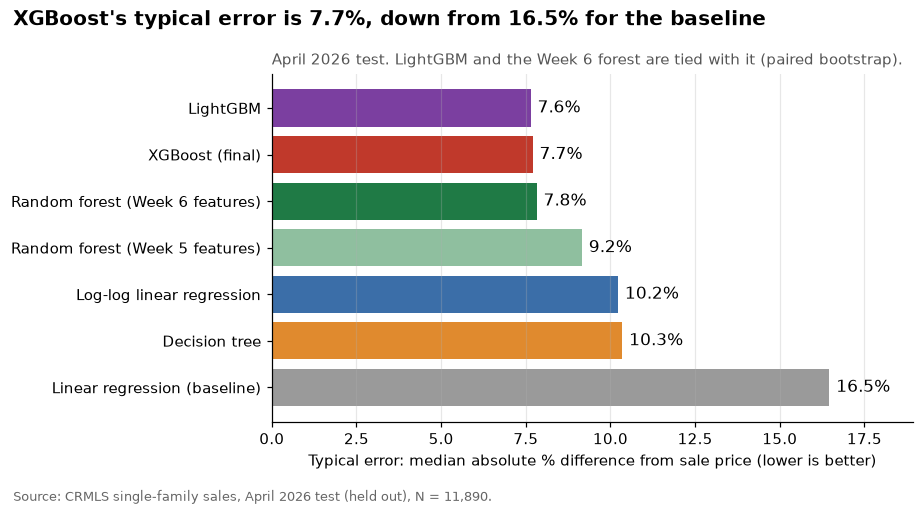

In [9]:
order = april["MdAPE_pct"].sort_values(ascending=False)  # barh draws bottom-up, best on top
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.barh([NAMES[m] for m in order.index], order, color=[COLORS[m] for m in order.index])
for y, value in enumerate(order):
    ax.text(value + 0.2, y, f"{value:.1f}%", va="center", fontsize=11)
ax.set(xlabel="Typical error: median absolute % difference from sale price (lower is better)",
       xlim=(0, order.max() * 1.15))
ax.grid(axis="y", visible=False)
avm.finish_chart(fig, ax, "XGBoost's typical error is 7.7%, down from 16.5% for the baseline", "April 2026 test. LightGBM and the Week 6 forest are tied with it (paired bootstrap).", SOURCE)
plt.show()

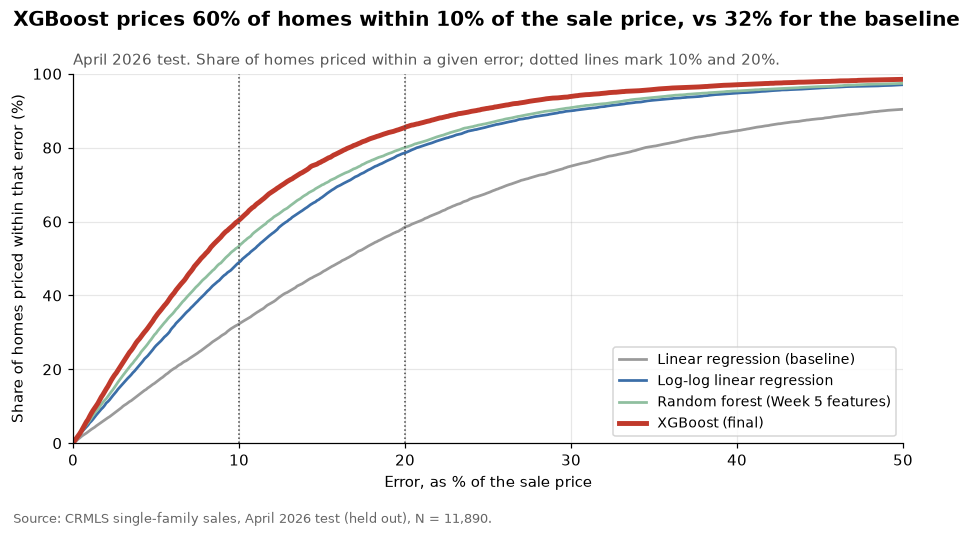

In [10]:
thresholds = np.linspace(0, 50, 501)
fig, ax = plt.subplots(figsize=(8.5, 4.8))
for name in STORY:
    ape = np.sort(inside[f"ape_{name}"].to_numpy())
    share = 100 * np.searchsorted(ape, thresholds, side="right") / len(ape)
    ax.plot(thresholds, share, color=COLORS[name], linewidth=WIDTH[name], label=NAMES[name])
for guide in (10, 20):
    ax.axvline(guide, color="#444444", linestyle=":", linewidth=1)
ax.set(xlabel="Error, as % of the sale price", ylabel="Share of homes priced within that error (%)",
       xlim=(0, 50), ylim=(0, 100))
ax.legend(loc="lower right", fontsize=9)
avm.finish_chart(fig, ax, "XGBoost prices 60% of homes within 10% of the sale price, vs 32% for the baseline",
                 "April 2026 test. Share of homes priced within a given error; dotted lines mark 10% and 20%.",
                 SOURCE)
plt.show()

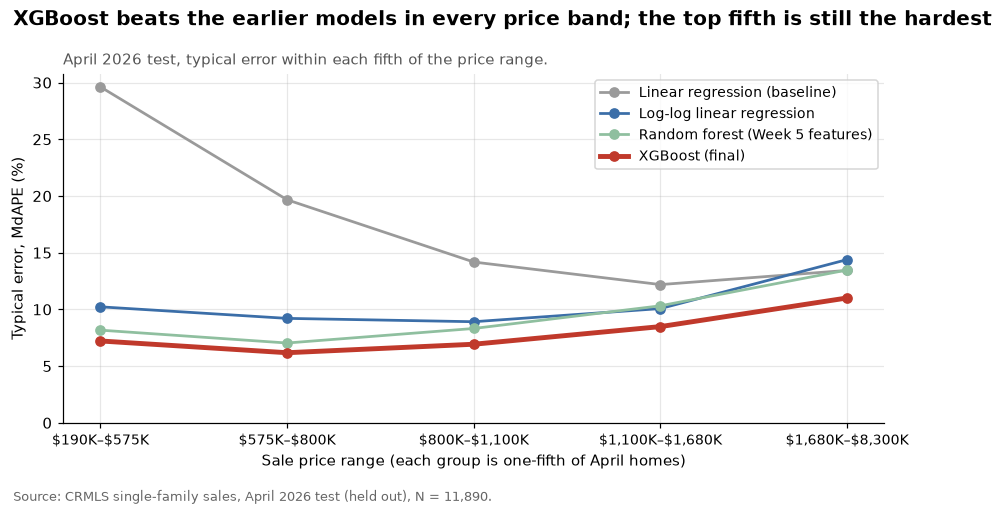

In [11]:
bands = pd.qcut(inside["ClosePrice"], 5)
band_labels = [f"${b.left / 1e3:,.0f}K–${b.right / 1e3:,.0f}K".replace("$", r"\$") for b in bands.cat.categories]
by_band = pd.DataFrame({name: inside.groupby(bands, observed=True)[f"ape_{name}"].median() for name in STORY})
fig, ax = plt.subplots(figsize=(8.5, 4.6))
for name in STORY:
    ax.plot(band_labels, by_band[name], marker="o", color=COLORS[name], linewidth=WIDTH[name], label=NAMES[name])
ax.set(xlabel="Sale price range (each group is one-fifth of April homes)", ylabel="Typical error, MdAPE (%)",
       ylim=(0, None))
ax.tick_params(axis="x", labelsize=9)
ax.legend(fontsize=9, loc="upper right")
avm.finish_chart(fig, ax, "XGBoost beats the earlier models in every price band; the top fifth is still the hardest", "April 2026 test, typical error within each fifth of the price range.",
                 SOURCE)
plt.show()

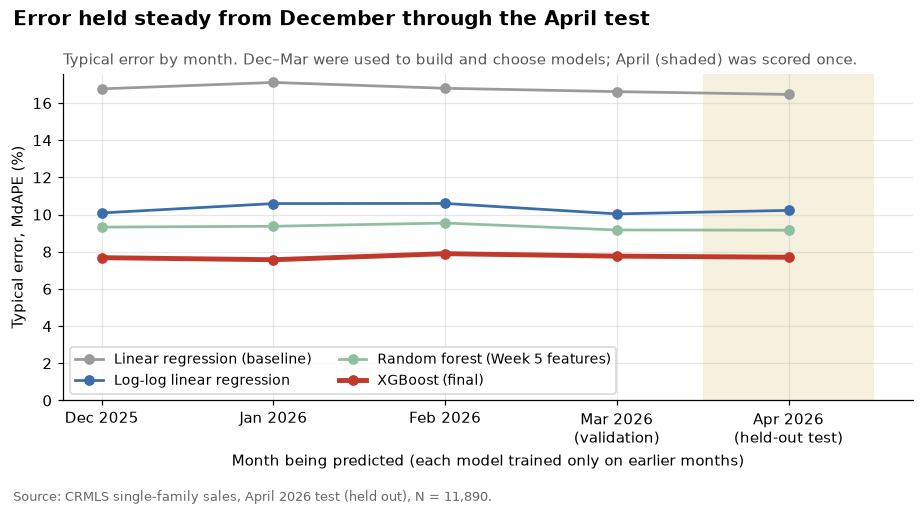

In [12]:
months = avm.TEAM_BACKTEST_MONTHS + [avm.TEAM_VAL_MONTH, avm.TEAM_TEST_MONTH]
month_labels = ["Dec 2025", "Jan 2026", "Feb 2026", "Mar 2026\n(validation)", "Apr 2026\n(held-out test)"]
by_month = summary.query("scope == 'filtered'").pivot(index="month", columns="model", values="MdAPE_pct").loc[months]
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.axvspan(3.5, 4.5, color="#f0e6c8", alpha=0.6, linewidth=0)
for name in STORY:
    ax.plot(month_labels, by_month[name], marker="o", color=COLORS[name], linewidth=WIDTH[name], label=NAMES[name])
ax.set(xlabel="Month being predicted (each model trained only on earlier months)",
       ylabel="Typical error, MdAPE (%)", ylim=(0, None))
ax.legend(fontsize=9, loc="lower left", ncols=2)
avm.finish_chart(fig, ax, "Error held steady from December through the April test",
                 "Typical error by month. Dec–Mar were used to build and choose models; April (shaded) was scored once.",
                 SOURCE)
plt.show()

**Sample homes.** Six real April sales picked at random (seed 42): one from each fifth of the price range, plus one from the top 1%. Each column shows a model's prediction with its error in brackets. Single homes vary a lot: the final model is best on average, not on every house.

In [13]:
def short_dollars(value):
    return f"${value / 1e6:.2f}M" if value >= 1e6 else f"${value / 1e3:,.0f}K"


top_cut = homes["ClosePrice"].quantile(0.99)
top_homes = homes.loc[homes["ClosePrice"] >= top_cut]
picked = pd.concat([
    inside.groupby(pd.qcut(inside["ClosePrice"], 5), observed=True).sample(1, random_state=42),
    top_homes.sample(1, random_state=42),
]).sort_values("ClosePrice")
samples = pd.DataFrame({
    "City": picked["City"].str.title(),
    "Sq ft": picked["LivingArea"].map(lambda v: "n/a" if pd.isna(v) else f"{v:,.0f}"),
    "Beds / baths": [f"{b:.0f} / {t:.0f}" if pd.notna(b) and pd.notna(t) else "n/a"
                     for b, t in zip(picked["BedroomsTotal"], picked["BathroomsTotalInteger"])],
    "Built": picked["YearBuilt"].map(lambda v: "n/a" if pd.isna(v) else f"{v:.0f}"),
    "Sale price": picked["ClosePrice"].map(short_dollars),
    **{NAMES[name]: [f"{short_dollars(p)} ({100 * (p - a) / a:+.0f}%)"
                     for p, a in zip(picked[f"pred_{name}"], picked["ClosePrice"])] for name in STORY},
}).reset_index(drop=True)
samples.index = ["Lowest fifth", "Second fifth", "Middle fifth", "Fourth fifth", "Top fifth", "Top 1%"]
display(samples)

,City,Sq ft,Beds / baths,Built,Sale price,Linear regression (baseline),Log-log linear regression,Random forest (Week 5 features),XGBoost (final)
Lowest fifth,Indio,"3,005",4 / 3,2006,$570K,$945K (+66%),$704K (+24%),$655K (+15%),$637K (+12%)
Second fifth,Ontario,"1,412",3 / 2,1976,$730K,$546K (-25%),$657K (-10%),$685K (-6%),$703K (-4%)
Middle fifth,Escondido,"1,375",4 / 2,1968,$820K,$582K (-29%),$731K (-11%),$768K (-6%),$756K (-8%)
Fourth fifth,Long Beach,"3,232",5 / 4,1964,$1.48M,$1.85M (+25%),$1.71M (+16%),$1.81M (+23%),$1.72M (+17%)
Top fifth,Westlake Village,"3,298",4 / 3,1974,$3.00M,$2.37M (-21%),$2.04M (-32%),$2.22M (-26%),$2.59M (-14%)
Top 1%,Corona Del Mar,"4,152",4 / 7,2026,$12.25M,$5.82M (-53%),$7.25M (-41%),$6.08M (-50%),$7.64M (-38%)


**What this means and next steps**

XGBoost is the model for the Week 9 app. On April, the held-out test month, it prices the typical home within 7.7% of its sale price, and it did as well on April as on every month used to build it. It fits in 3 seconds and saves to a 4 MB file. LightGBM and the Week 6 random forest are statistically tied with it, so the choice between them rests on size and speed, not accuracy.

Known limits, which the app should state:

- It cannot predict above $8.30M, the top of its training range, and it under-predicts the top 1% of homes by a median of 38%.
- Accuracy is lower for older homes and in the Bay Area, especially Oakland.
- It has no time trend, so in a rising market its estimates lag slightly: a median of −1.9% in April.

Next steps:

- Add a time feature (months since the start of the data) or weight recent sales more, to remove the lag.
- Give the most expensive homes more detail, such as lot size relative to the neighborhood or view and waterfront flags, after a leakage review.
- Rerun this notebook when May 2026 arrives, with May as the new test month.

Files written: `results/metrics_summary.csv` (every model × month × scope, 70 rows), `results/april_bootstrap.csv` and `results/april_test_context.json`. The per-sale April predictions are in `results/april_predictions.csv`, which git ignores because it contains CRMLS records.